[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/IMForg-Public/imf_big_data_workshop_sti26/blob/main/notebooks/BDC_Working_With_AIS_PortWatch.ipynb)

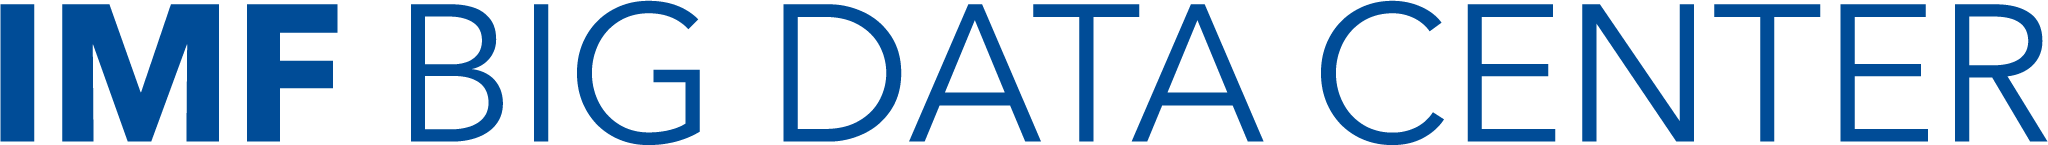

# Accessing PortWatch API

---

<br>**Contributors:** [Alessandra Sozzi](asozzi@imf.org), [Dharana Rijal](drijal@imf.org) & [Mario Saraiva](msaraiva@imf.org)
<br> **Last update:** Oct-2026
<br> **Description:** This notebook showcases how to use the PortWatch API to download data. Then it gives different examples on how to use the data. In a fast-changing world of frequent disruptions, journalists, economists, policy-makers, and others need access to real-time data to make informed decisions during crises. This is where PortWatch comes in. Leveraging satellite-based vessel data and advanced big data analytics, PortWatch provides unparalleled insights into the domestic and international trade impacts of both current and future disasters.
<br> **References:** https://portwatch.imf.org/

## Working with Portwatch

### Objectives
- Using the Portwatch API to query data
- Create visualizations for different indicators (portcalls etc.)
- Create a simple monitor

<details>
<summary><b>The data behind PortWatch</b> </summary>

PortWatch is based on Automatic Identification System (AIS) - is a system that allows ships to automatically transmit key information, such as position, speed, and identity, to other ships and shore stations. While it was originally developed as an anti-collision system, it has also evolved to act as a traffic control system for vessels, enhancing safety and operational efficiency.

Every ship is required to carry an AIS transmitter. These devices typically send positioning messages as frequently as every 2 to 10 seconds, depending on the ship's speed and the system configuration. While it's common to say that AIS acts like a "traffic control system for ships," it's important to note that the frequency of messages can vary based on the ship's movement.

</details>

### Using the Portwatch API
The datasets used in this notebook are available through the PortWatch API. Each dataset is queried by its service ID:

| Dataset | Service ID | Description |
|---|---|---|
| [Daily Port Activity Data and Trade Estimates](https://portwatch.imf.org/datasets/83b1bbc7b3354c5fb1f40673bb8f852e/about) | `Daily_Ports_Data` | Daily port calls and estimated import and export volumes by vessel type for ports worldwide, based on satellite AIS signals from about 90,000 ships. Updated weekly. |
| [Daily Chokepoint Transit Calls and Trade Volume Estimates](https://portwatch.imf.org/datasets/3da2b9ca97684916b75c4013f95d18ab/about) | `Daily_Chokepoints_Data` | Daily transit calls and estimated transit trade volumes (metric tons) for 28 chokepoints around the world. Updated weekly. |
| [Ports](https://portwatch.imf.org/datasets/acc668d199d1472abaaf2467133d4ca4/about) | `PortWatch_ports_database` | PortWatch ports database: location, country, vessel counts and top industries for each port. |
| [Chokepoints](https://portwatch.imf.org/datasets/fa9a5800b0ee4855af8b2944ab1e07af/about) | `PortWatch_chokepoints_database` | Additional information on the 28 major global chokepoints identified by PortWatch. |

More details on the data and methodology are available [here](https://portwatch.imf.org/pages/data-and-methodology).


## Setup

#### Mount the drive and adjust the path

In [ ]:
# Mount the drive to access files in the Google Drive folder
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
# Set the main path for the workshop files

import os

ROOT = "/content/drive/MyDrive/BDMS_STI_2026-main/"
data_path = os.path.join(ROOT, "data", "3b_portwatch")
portwatch_library_dir = os.path.join(ROOT, "portwatch_py")

# Check if working
print("Data path found: ", os.path.exists(data_path))
print("File path found: ", os.path.exists(portwatch_library_dir))

Data path found:  True
File path found:  True


### Libraries

<H4> Installing Additional Library </H4>

In [ ]:
import time
import json
import requests
import pandas as pd
from datetime import datetime

import plotly.express as px
import ipywidgets as widgets
from IPython.display import display

In [ ]:
import geopandas as gpd
from shapely.geometry import Point

<H4> PortWatch API Wrapper Functions </H4>

In [ ]:
#This allow us to source the functions in the query_portwatch_api.py file
import sys
sys.path.append(portwatch_library_dir)

from query_portwatch_api import query_portwatch

## Chokepoints
In the following example we will query data from the Daily Chokepoint Transit Calls and Trade Volume Estimates <a href="https://portwatch.imf.org/datasets/42132aa4e2fc4d41bdaf9a445f688931/about">dataset</a>. Full list of chokepoints is available <a href="https://portwatch.imf.org/datasets/fa9a5800b0ee4855af8b2944ab1e07af/about">here</a>.

#### 2.1 All Chokepoints covered in PortWatch

In [ ]:
# Query the list with all Chokepoints metadata information
chokepoints_metadata = query_portwatch("PortWatch_chokepoints_database")
chokepoints_metadata

Querying PortWatch data PortWatch_chokepoints_database...
https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/PortWatch_chokepoints_database/FeatureServer/0/query
{'where': '1=1', 'returnCountOnly': True, 'outFields': '*', 'f': 'json'}
Begin extraction of 28 number of records...
Extracting batch of 5000 starting at record 0...
https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/PortWatch_chokepoints_database/FeatureServer/0/query
{'where': '1=1', 'maxRecordCountFactor': 5, 'outFields': '*', 'f': 'json', 'resultOffset': 0}


,portid,portname,country,ISO3,continent,fullname,lat,lon,vessel_count_total,vessel_count_container,...,vessel_count_RoRo,vessel_count_tanker,industry_top1,industry_top2,industry_top3,share_country_maritime_import,share_country_maritime_export,LOCODE,pageid,countrynoaccents
0,chokepoint1,Suez Canal,None,None,None,Suez Canal,30.593346,32.436882,19787,5513,...,766,6418,Mineral Products,Vegetable Products,Chemical & Allied Industries,None,None,None,c57c79bf612b4372b08a9c6ea9c97ef0,None
1,chokepoint2,Panama Canal,None,None,None,Panama Canal,9.120512,-79.767238,11020,2712,...,770,4507,Mineral Products,Vegetable Products,Chemical & Allied Industries,None,None,None,44d73fd00bbc4f73a16d46d5beb11b4d,None
2,chokepoint3,Bosporus Strait,None,None,None,Bosporus Strait,41.169282,29.091501,35125,3015,...,264,8555,Mineral Products,Vegetable Products,Chemical & Allied Industries,None,None,None,837f298c756a4efd85e3fabe31e319ac,None
3,chokepoint4,Bab el-Mandeb Strait,None,None,None,Bab el-Mandeb Strait,12.788597,43.349545,19306,5062,...,904,6424,Mineral Products,Chemical & Allied Industries,Vegetable Products,None,None,None,6b1814d64903461b98144a6cc25eb79c,None
4,chokepoint5,Malacca Strait,None,None,None,Malacca Strait,1.516955,102.665106,71451,18154,...,2256,27469,Mineral Products,Chemical & Allied Industries,Vegetable Products,None,None,None,5f51a0d85ac44a6bad02561e25899c4a,None
5,chokepoint6,Strait of Hormuz,None,None,None,Strait of Hormuz,26.296853,56.859848,32496,5274,...,856,19540,Mineral Products,Chemical & Allied Industries,Vegetable Products,None,None,None,cb5856222a5b4105adc6ee7e880a1730,None
6,chokepoint7,Cape of Good Hope,None,None,None,Cape of Good Hope,-34.927286,20.882737,21531,3493,...,628,4706,Mineral Products,Vegetable Products,Prepared Foodstuffs & Beverages,None,None,None,edf18f455a2b4637a3632b6af201abe9,None
7,chokepoint8,Gibraltar Strait,None,None,None,Gibraltar Strait,35.942274,-5.754896,47801,11698,...,1883,15666,Mineral Products,Vegetable Products,Chemical & Allied Industries,None,None,None,d2b71882a70449288ee9bd15421d2aa9,None
8,chokepoint9,Dover Strait,None,None,None,Dover Strait,51.030224,1.505840,60580,12535,...,4118,21126,Mineral Products,Chemical & Allied Industries,Vegetable Products,None,None,None,34a9c079e9e14b19a1ca9f218f368d12,None
9,chokepoint10,Oresund Strait,None,None,None,Oresund Strait,55.507840,12.850795,17833,2135,...,1170,4318,Mineral Products,Wood & Wood Products,Chemical & Allied Industries,None,None,None,65ec417b135745d0924b2c0d68649d1a,None


#### 2.2. Map of all Chokepoints



In [ ]:
chokepoints_metadata.columns

Index(['portid', 'portname', 'country', 'ISO3', 'continent', 'fullname', 'lat',
       'lon', 'vessel_count_total', 'vessel_count_container',
       'vessel_count_dry_bulk', 'vessel_count_general_cargo',
       'vessel_count_RoRo', 'vessel_count_tanker', 'industry_top1',
       'industry_top2', 'industry_top3', 'share_country_maritime_import',
       'share_country_maritime_export', 'LOCODE', 'pageid',
       'countrynoaccents'],
      dtype='object')

In [ ]:
# Plot all chokepoints by converting lat and long into Points
chokepoints_metadata_geo = gpd.GeoDataFrame(
    chokepoints_metadata,
    geometry=gpd.points_from_xy(chokepoints_metadata.lon, chokepoints_metadata.lat),
    crs="EPSG:4326"
)
chokepoints_metadata_geo.explore(tiles="Esri.WorldGrayCanvas", color="red")

#### 2.3. Query Daily Chokepoint Transit Calls and Trade Volume Estimates for 1 Chokepoint

In [ ]:
# See for list of chokepoint-portid correspondance
one_chokepoint = query_portwatch("Daily_Chokepoints_Data", where="portid='chokepoint26'") # Can try different chokepoints
one_chokepoint.tail()

Querying PortWatch data Daily_Chokepoints_Data...
https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Chokepoints_Data/FeatureServer/0/query
{'where': "portid='chokepoint26'", 'returnCountOnly': True, 'outFields': '*', 'f': 'json'}
Begin extraction of 2855 number of records...
Extracting batch of 5000 starting at record 0...
https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Chokepoints_Data/FeatureServer/0/query
{'where': "portid='chokepoint26'", 'maxRecordCountFactor': 5, 'outFields': '*', 'f': 'json', 'resultOffset': 0}


,date,year,month,day,portid,portname,n_container,n_dry_bulk,n_general_cargo,n_roro,n_tanker,n_cargo,n_total,capacity_container,capacity_dry_bulk,capacity_general_cargo,capacity_roro,capacity_tanker,capacity_cargo,capacity
2850,2026-10-21,2026,10,21,chokepoint26,Bering Strait,0,1,0,0,3,1,4,0,70316,0,0,16119,70316,86435
2851,2026-10-22,2026,10,22,chokepoint26,Bering Strait,0,0,1,0,2,1,3,0,0,416,0,0,416,416
2852,2026-10-23,2026,10,23,chokepoint26,Bering Strait,0,0,0,0,2,0,2,0,0,0,0,106260,0,106260
2853,2026-10-24,2026,10,24,chokepoint26,Bering Strait,0,0,1,0,2,1,3,0,0,0,0,81615,0,81615
2854,2026-10-25,2026,10,25,chokepoint26,Bering Strait,0,0,1,0,1,1,2,0,0,3566,0,0,3566,3566


#### 2.4. Save Extraction

In [ ]:
one_chokepoint.to_csv(
    os.path.join(data_path, "chokepoint_via_api.csv"),
    index=False
)

#### 2.5. Plot Daily Data

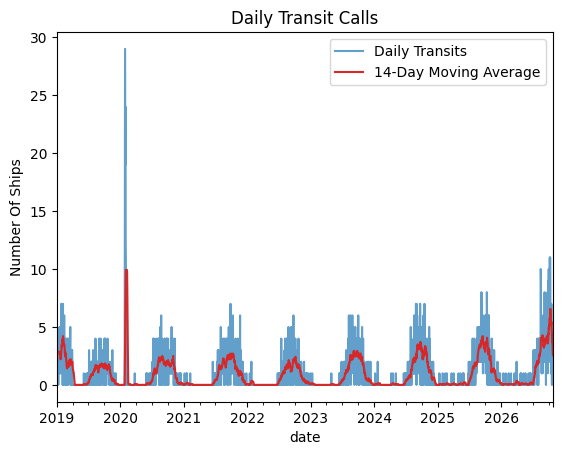

In [ ]:
# Simple Plot of Transit Calls
ax = one_chokepoint.set_index(['date'])['n_total'].plot( # can change to capacity
    title='Daily Transit Calls',
    xlabel='',
    ylabel='Number Of Ships',
    alpha=0.7,
    label='Daily Transits'
)
one_chokepoint.set_index(['date'])['n_total'].rolling(14).mean().plot(
    ax=ax, color='#d62828', label='14-Day Moving Average')
ax.legend();

#### 2.6 Red Sea And Hormuz Chart

In [ ]:
suez_canal = query_portwatch("Daily_Chokepoints_Data", where="portid='chokepoint1'")
suez_canal.shape

Querying PortWatch data Daily_Chokepoints_Data...
https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Chokepoints_Data/FeatureServer/0/query
{'where': "portid='chokepoint1'", 'returnCountOnly': True, 'outFields': '*', 'f': 'json'}
Begin extraction of 2855 number of records...
Extracting batch of 5000 starting at record 0...
https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Chokepoints_Data/FeatureServer/0/query
{'where': "portid='chokepoint1'", 'maxRecordCountFactor': 5, 'outFields': '*', 'f': 'json', 'resultOffset': 0}


(2855, 20)

In [ ]:
cape_good_hope = query_portwatch("Daily_Chokepoints_Data", where="portid='chokepoint7'")
cape_good_hope.shape

Querying PortWatch data Daily_Chokepoints_Data...
https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Chokepoints_Data/FeatureServer/0/query
{'where': "portid='chokepoint7'", 'returnCountOnly': True, 'outFields': '*', 'f': 'json'}
Begin extraction of 2855 number of records...
Extracting batch of 5000 starting at record 0...
https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Chokepoints_Data/FeatureServer/0/query
{'where': "portid='chokepoint7'", 'maxRecordCountFactor': 5, 'outFields': '*', 'f': 'json', 'resultOffset': 0}


(2855, 20)

In [ ]:
strait_of_hormuz = query_portwatch("Daily_Chokepoints_Data", where="portid='chokepoint6'")
strait_of_hormuz.shape

Querying PortWatch data Daily_Chokepoints_Data...
https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Chokepoints_Data/FeatureServer/0/query
{'where': "portid='chokepoint6'", 'returnCountOnly': True, 'outFields': '*', 'f': 'json'}
Begin extraction of 2855 number of records...
Extracting batch of 5000 starting at record 0...
https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Chokepoints_Data/FeatureServer/0/query
{'where': "portid='chokepoint6'", 'maxRecordCountFactor': 5, 'outFields': '*', 'f': 'json', 'resultOffset': 0}


(2855, 20)

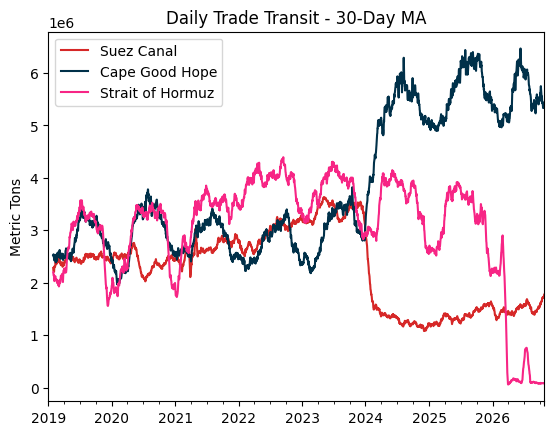

In [ ]:
ax = suez_canal.set_index(['date'])['capacity'].rolling(30).mean().plot( # 30-day MA
    label='Suez Canal',
    color='#d62828'
)
cape_good_hope.set_index(['date'])['capacity'].rolling(30).mean().plot(
    ax=ax,
    label='Cape Good Hope',
    color='#003049'
)
strait_of_hormuz.set_index(['date'])['capacity'].rolling(30).mean().plot(
    ax=ax,
    label='Strait of Hormuz',
    color="#f72585"
)
ax.set_ylabel('Metric Tons')
ax.set_xlabel('')
ax.set_title('Daily Trade Transit - 30-Day MA')
ax.legend();

In [ ]:
# Interactive version
# One column per chokepoint, 30-day moving average
transit = pd.DataFrame({
    "Suez Canal": suez_canal.set_index("date")["capacity"],
    "Cape Good Hope": cape_good_hope.set_index("date")["capacity"],
    "Strait of Hormuz": strait_of_hormuz.set_index("date")["capacity"]
}).rolling(30).mean()

fig = px.line(
    transit,
    title="Daily Trade Transit - 30-Day MA",
    labels={"value": "Metric Tons", "date": "", "variable": "Chokepoint"},
    color_discrete_sequence=["#d62828", "#003049", "#f72585"],
)
fig.show()

## Ports
In the following example we will query data from the Daily Port Activity and Trade Estimates <a href="https://portwatch.imf.org/datasets/75619cb86e5f4beeb7dab9629d861acf/about">dataset</a> and try to build country monitor

#### 3.1 All Ports covered in PortWatch

In [ ]:
# Query the list with all Chokepoints metadata information
ports_metadata = query_portwatch("PortWatch_ports_database")
ports_metadata

Querying PortWatch data PortWatch_ports_database...
https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/PortWatch_ports_database/FeatureServer/0/query
{'where': '1=1', 'returnCountOnly': True, 'outFields': '*', 'f': 'json'}
Begin extraction of 2065 number of records...
Extracting batch of 5000 starting at record 0...
https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/PortWatch_ports_database/FeatureServer/0/query
{'where': '1=1', 'maxRecordCountFactor': 5, 'outFields': '*', 'f': 'json', 'resultOffset': 0}


,portid,portname,country,ISO3,continent,fullname,lat,lon,vessel_count_total,vessel_count_container,...,vessel_count_RoRo,vessel_count_tanker,industry_top1,industry_top2,industry_top3,share_country_maritime_import,share_country_maritime_export,LOCODE,pageid,countrynoaccents
0,port1325,Tsuruga,Japan,JPN,Asia & Pacific,"Tsuruga, Japan",35.667194,136.070611,529,77,...,187,54,Mineral Products,Wood & Wood Products,Vegetable Products,0.42,0.09,JP TRG,3b1f40eb8acd452ab6229331302891fe,Japan
1,port1198,Sibolga,Indonesia,IDN,Asia & Pacific,"Sibolga, Indonesia",1.734969,98.781715,81,28,...,8,39,Mineral Products,Prepared Foodstuffs & Beverages,Vegetable Products,0.08,0.01,ID SLG,4d00b008b4be4068bf8a19d7da6e8cf6,Indonesia
2,port339,Fangcheng,China,CHN,Asia & Pacific,"Fangcheng, China",21.614205,108.364339,1968,34,...,0,211,Mineral Products,Chemical & Allied Industries,Vegetable Products,1.90,0.42,CN FAN,266042b244cf452a89f4a2de14f3da2f,China
3,port1335,Ube,Japan,JPN,Asia & Pacific,"Ube, Japan",33.944875,131.213184,4799,13,...,0,2089,Mineral Products,Chemical & Allied Industries,"Plastics, Rubber, Leather",0.76,2.35,JP UBJ,f3f6725ef00e4d3f8f9c93c45258667e,Japan
4,port153,Bluff Harbor,New Zealand,NZL,Asia & Pacific,"Bluff Harbor, New Zealand",-46.590130,168.360216,240,43,...,0,58,Wood & Wood Products,Metals,Prepared Foodstuffs & Beverages,7.79,2.84,None,894ab5e5a18e48b6922c023196f74c8f,New Zealand
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2060,port2504,Wenzhou Huagang,China,CHN,Asia & Pacific,"Wenzhou Huagang, China",27.899172,121.121785,0,0,...,0,0,None,None,None,0.00,0.00,None,a8a977de488c464bbcd1e55abba728e3,China
2061,port2505,Wenzhou LNG Terminal,China,CHN,Asia & Pacific,"Wenzhou LNG Terminal, China",28.006254,121.072934,0,0,...,0,0,None,None,None,0.00,0.00,None,0e516a60f7524828ab9ec768d7bf4231,China
2062,port2506,Woodfibre LNG Terminal,Canada,CAN,North America,"Woodfibre LNG Terminal, Canada",49.664645,-123.251629,0,0,...,0,0,None,None,None,0.00,0.00,None,4a60188780884b038db8f78ffe61b151,Canada
2063,port2507,Yancheng,China,CHN,Asia & Pacific,"Yancheng, China",34.296970,120.278559,0,0,...,0,0,None,None,None,0.00,0.00,None,e83c0354a80b448f9bbaf14bb0f0f3ef,China


#### 3.2. Map of all Ports

In [ ]:
# Plot all chokepoints by converting lat and long into Points
ports_metadata_geo = gpd.GeoDataFrame(
    ports_metadata,
    geometry=gpd.points_from_xy(ports_metadata.lon, ports_metadata.lat),
    crs="EPSG:4326"
)
ports_metadata_geo.explore(tiles="Esri.WorldGrayCanvas", color="red")

#### 3.3 Query Daily Port Activity Data and Trade Estimates for 1 Port

In [ ]:
iso3 = "UKR"
country_ports = gpd.GeoDataFrame(
    ports_metadata[ports_metadata['ISO3']==iso3],
    geometry=gpd.points_from_xy(ports_metadata[ports_metadata['ISO3']==iso3].lon,
                                ports_metadata[ports_metadata['ISO3']==iso3].lat),
    crs="EPSG:4326"
)

print(country_ports.shape)

country_ports.explore(tiles="Esri.WorldGrayCanvas", color="red")

(16, 23)


In [ ]:
country_ports

,portid,portname,country,ISO3,continent,fullname,lat,lon,vessel_count_total,vessel_count_container,...,vessel_count_tanker,industry_top1,industry_top2,industry_top3,share_country_maritime_import,share_country_maritime_export,LOCODE,pageid,countrynoaccents,geometry
1083,port135,Berdyansk,Ukraine,UKR,Europe,"Berdyansk, Ukraine",46.752471,36.776569,116,2,...,2,Mineral Products,Vegetable Products,Metals,0.13,0.69,None,09047a11096d49a9abb3202cb6c9c56e,Ukraine,POINT (36.77657 46.75247)
1086,port489,Chornomorsk,Ukraine,UKR,Europe,"Chornomorsk, Ukraine",46.331599,30.656566,711,74,...,74,Vegetable Products,Mineral Products,Prepared Foodstuffs & Beverages,12.15,18.74,UA ILK,ab188f0a4a4c49a8970328d919530344,Ukraine,POINT (30.65657 46.3316)
1089,port559,Kerch,Ukraine,UKR,Europe,"Kerch, Ukraine",45.337536,36.463934,547,2,...,151,Mineral Products,Chemical & Allied Industries,Prepared Foodstuffs & Beverages,8.46,12.37,UA KEH,1cc88374479846bcb0e669e478e3e562,Ukraine,POINT (36.46393 45.33754)
1092,port707,Mariupol,Ukraine,UKR,Europe,"Mariupol, Ukraine",47.054354,37.505079,274,5,...,15,Mineral Products,Chemical & Allied Industries,Metals,0.20,2.07,UA MPW,a8d27289787d4b23a7ca7b9530d665ab,Ukraine,POINT (37.50508 47.05435)
1095,port782,Mykolaiv,Ukraine,UKR,Europe,"Mykolaiv, Ukraine",46.939475,32.015560,366,5,...,71,Mineral Products,Vegetable Products,Metals,2.88,8.48,UA NLV,82732d70884347bb858a2d1d65100f0b,Ukraine,POINT (32.01556 46.93947)
1098,port843,Odessa,Ukraine,UKR,Europe,"Odessa, Ukraine",46.501283,30.738071,692,178,...,56,Mineral Products,Vegetable Products,Chemical & Allied Industries,13.07,13.88,UA ODS,279b4ea79a064231bdec508f1437c13c,Ukraine,POINT (30.73807 46.50128)
1101,port1419,Pivdennyi,Ukraine,UKR,Europe,"Pivdennyi, Ukraine",46.633347,31.018057,597,61,...,109,Vegetable Products,Mineral Products,Prepared Foodstuffs & Beverages,27.58,32.16,UA YUZ,007a49ba90c14de5ab525d82f091d549,Ukraine,POINT (31.01806 46.63335)
1377,port2001,Izmail,Ukraine,UKR,Europe,"Izmail, Ukraine",45.336104,28.809837,483,11,...,80,None,None,None,2.84,1.44,UA IZM,c0798af2e46a462a997daed4365facce,Ukraine,POINT (28.80984 45.3361)
1378,port2002,Reni,Ukraine,UKR,Europe,"Reni, Ukraine",45.424052,28.290122,407,16,...,80,None,None,None,1.30,1.52,UA RNI,bb2b3541b36142d3b9988dac872c6898,Ukraine,POINT (28.29012 45.42405)
1379,port2003,Olvia,Ukraine,UKR,Europe,"Olvia, Ukraine",46.810047,31.954398,422,6,...,45,None,None,None,27.50,7.04,None,0326e36f0a544523a85ac28bead67361,Ukraine,POINT (31.9544 46.81005)


In [ ]:
# Query One Port
# See for list of portid correspondance
one_port = query_portwatch("Daily_Ports_Data", where="portid='port489'") # Can try different port
one_port.tail()

Querying PortWatch data Daily_Ports_Data...
https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Ports_Data/FeatureServer/0/query
{'where': "portid='port489'", 'returnCountOnly': True, 'outFields': '*', 'f': 'json'}
Begin extraction of 0 number of records...


""


#### 3.4. Save Extraction

In [ ]:
one_port.to_csv(
    os.path.join(data_path, "port_via_api.csv"),
    index=False
)

#### 3.5. Plot Daily Data

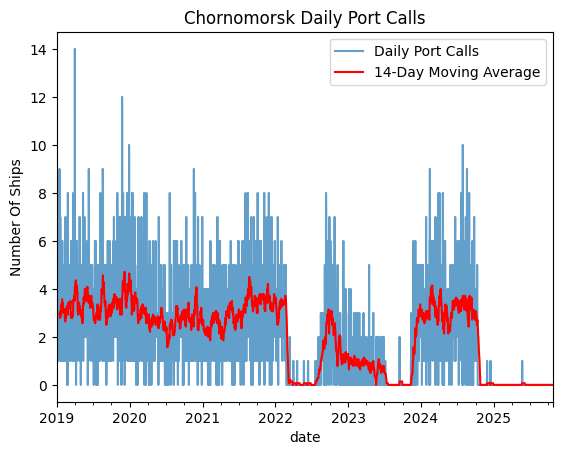

In [ ]:
# Simple Plot of Portcalls
ax = one_port.set_index(['date'])['portcalls'].plot( # can change to import/export
    title=f'{one_port.iloc[0].portname} Daily Port Calls',
    xlabel='',
    ylabel='Number Of Ships',
    alpha=0.7,
    label='Daily Port Calls'
)
one_port.set_index(['date'])['portcalls'].rolling(14).mean().plot(
    ax=ax, color='red', label='14-Day Moving Average')
ax.legend();

#### By Ship Type

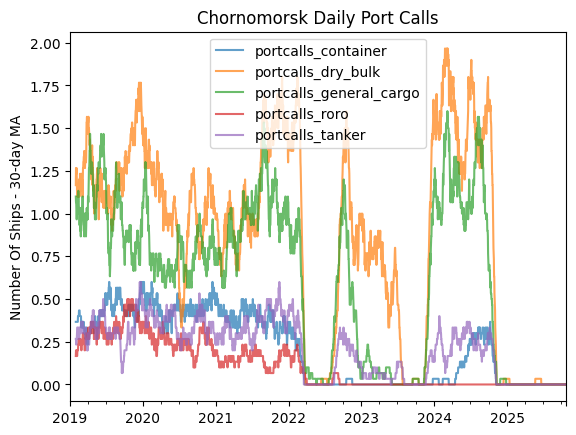

In [ ]:
ax = one_port.set_index(['date'])[
    ['portcalls_container', 'portcalls_dry_bulk',
     'portcalls_general_cargo', 'portcalls_roro',
     'portcalls_tanker']
    ].rolling(30).mean().plot( # can change to import/export
    title=f'{one_port.iloc[0].portname} Daily Port Calls',
    xlabel='',
    ylabel='Number Of Ships - 30-day MA',
    alpha=0.7,
    legend=True
)
ax.legend();

## Creating a Country monitoring dashboard

#### 4.1 Data Extraction

In [ ]:
country = 'Ukraine'

In [ ]:
df_trade = query_portwatch("Daily_Trade_Data", where=f"country='{country}'") #change country name to any country you want to query data for

Querying PortWatch data Daily_Trade_Data...
https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Trade_Data/FeatureServer/0/query
{'where': "country='Ukraine'", 'returnCountOnly': True, 'outFields': '*', 'f': 'json'}
Begin extraction of 37335 number of records...
Extracting batch of 5000 starting at record 0...
https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Trade_Data/FeatureServer/0/query
{'where': "country='Ukraine'", 'maxRecordCountFactor': 5, 'outFields': '*', 'f': 'json', 'resultOffset': 0}
Extracting batch of 5000 starting at record 5000...
https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Trade_Data/FeatureServer/0/query
{'where': "country='Ukraine'", 'maxRecordCountFactor': 5, 'outFields': '*', 'f': 'json', 'resultOffset': 5000}
Extracting batch of 5000 starting at record 10000...
https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Trade_Data/FeatureServer/0/query
{'where': "country='Ukrai

In [ ]:
df_trade.head()

,date,year,month,day,portid,portname,country,ISO3,portcalls_container,portcalls_dry_bulk,...,import_tanker,import_cargo,import,export_container,export_dry_bulk,export_general_cargo,export_roro,export_tanker,export_cargo,export
0,2019-01-01,2019,1,1,port135,Berdyansk,Ukraine,UKR,0,0,...,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000
1,2019-01-01,2019,1,1,port489,Chornomorsk,Ukraine,UKR,0,0,...,0.0,0.000000,0.000000,0.000000,0.000000,6149.740684,0.0,0.0,6149.740684,6149.740684
2,2019-01-01,2019,1,1,port2077,Bilhorod-Dnistrovskyi,Ukraine,UKR,0,0,...,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000
3,2019-01-01,2019,1,1,port2234,Feodosiya,Ukraine,UKR,0,0,...,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000
4,2019-01-01,2019,1,1,port843,Odesa,Ukraine,UKR,2,1,...,0.0,1303.845559,1303.845559,5312.345034,61543.726629,0.000000,0.0,0.0,66856.071663,66856.071663


In [ ]:
df_trade.to_csv(
    os.path.join(data_path, f"trade_data.csv"),
    index=False
)

In [ ]:
# List of ports in the dataset
print("Extracted", df_trade.portname.nunique(), "ports")
df_trade.portname.unique()

Extracted 15 ports


array(['Berdyansk', 'Chornomorsk', 'Bilhorod-Dnistrovskyi', 'Feodosiya',
       'Odesa', 'Kerch', 'Reni', 'Mykolaiv', 'Kherson',
       'Port of Skadovsk', 'Mariupol', 'Pivdennyi', 'Izmail', 'Olvia',
       'Ust-Danube'], dtype=object)

In [ ]:
df_trade.shape

(37335, 29)

#### 4.2 Data handling

In [ ]:
# Calculating daily aggregates
def prepare_daily_data(df, ma=30):
    # Group by date, and portname and calculate the sum for total import and export
    daily_aggregates = df.groupby(['date'])[['import','export']].sum().rolling(ma).mean()
    return daily_aggregates

#### 4.3 Dashboard

In [ ]:
# If needed on Colab, uncomment these:
# !pip install ipywidgets
# from google.colab import output as _colab_output; _colab_output.enable_custom_widget_manager()

import ipywidgets as widgets
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

# ---- Widgets ----
portname_dropdown = widgets.Dropdown(
    options=[('Ukraine', '')] + [(portname, portname) for portname in df_trade['portname'].sort_values().unique()],
    description='Port Name:',
    value='',  # default: all ports
)

date_min = pd.to_datetime(df_trade['date'].min()).normalize()
date_max = pd.to_datetime(df_trade['date'].max()).normalize()
date_index = pd.date_range(start=date_min, end=date_max, freq='D')

date_slider = widgets.SelectionRangeSlider(
    options=[(date.strftime('%Y/%m/%d'), date) for date in date_index],
    index=(0, len(date_index) - 1),
    description='Date Range:',
    continuous_update=False,   # update when you release the handle
    layout=widgets.Layout(width='600px')
)

output = widgets.Output()

# ---- Update function ----
def render(_=None):
    with output:
        clear_output(wait=True)
        portname = portname_dropdown.value
        start_date, end_date = date_slider.value

        try:
            # Filter
            mask = df_trade['date'].between(start_date, end_date)
            filtered_df = df_trade.loc[mask]
            if portname != '':
                filtered_df = filtered_df.loc[filtered_df['portname'] == portname]

            # Prepare daily aggregates (expects columns: 'import', 'export'; index = date)
            daily_aggregates = prepare_daily_data(filtered_df)
            if daily_aggregates is None or daily_aggregates.empty:
                print("No data for the selected filters.")
                return

            daily_aggregates = daily_aggregates.copy()
            daily_aggregates.index = pd.to_datetime(daily_aggregates.index)
            daily_aggregates = daily_aggregates.sort_index()

            # Plot
            fig, ax = plt.subplots(figsize=(10, 5))
            ax.plot(daily_aggregates.index, daily_aggregates['import'], label='Imports', marker='o', linewidth=1)
            ax.plot(daily_aggregates.index, daily_aggregates['export'], label='Exports', marker='o', linewidth=1)

            title_port = portname if portname != '' else 'All Ports'
            ax.set_title(f'Total Import and Export for {title_port}')
            ax.set_xlabel('Date')
            ax.set_ylabel('Metric Tons')
            ax.legend()
            ax.grid(True, alpha=0.3)
            fig.autofmt_xdate()
            plt.tight_layout()
            display(fig)
            plt.close(fig)

        except Exception as e:
            print(f"An error occurred: {e}")

# ---- Wire up auto-update ----
portname_dropdown.observe(render, names='value')
date_slider.observe(render, names='value')

# ---- Layout & initial draw ----
controls = widgets.VBox([portname_dropdown, date_slider])
display(controls, output)
render()  # initial render


Output()